In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)
import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("credit_risk_dataset.csv")

In [3]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


### Column description

| Feature | Description |
|----------|-------------|
| **person_age** | Age of the loan applicant in years. |
| **person_income** | Annual income of the loan applicant. |
| **person_home_ownership** | Home ownership status of the applicant. |
| **person_emp_length** | Number of years the applicant has been employed. |
| **loan_intent** | Purpose for which the loan was taken. |
| **loan_grade** | Credit risk grade assigned to the loan applicant. |
| **loan_amnt** | Amount of money borrowed as a loan. |
| **loan_int_rate** | Interest rate charged on the loan. |
| **loan_status** | Status of the loan. |
| **loan_percent_income** | Percentage of annual income represented by the loan amount. |
| **cb_person_default_on_file** | Indicates whether the applicant has a previous credit default history. |
| **cb_person_cred_hist_length** | Length of the applicant's credit history in years. |

In [4]:
df.dtypes

person_age                      int64
person_income                   int64
person_home_ownership          object
person_emp_length             float64
loan_intent                    object
loan_grade                     object
loan_amnt                       int64
loan_int_rate                 float64
loan_status                     int64
loan_percent_income           float64
cb_person_default_on_file      object
cb_person_cred_hist_length      int64
dtype: object

In [5]:
df.shape

(32581, 12)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [7]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [8]:
df.loc[df["person_age"] > 100,"person_age"] = np.nan
df.loc[df["person_emp_length"] > (df["person_age"] - 18),"person_emp_length"] = np.nan

In [9]:
df.isnull().sum()

person_age                       5
person_income                    0
person_home_ownership            0
person_emp_length             8731
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(165)

In [11]:
df.drop_duplicates(inplace=True)

In [12]:
num_cols = df.select_dtypes(include=["int64","float64"]).columns.drop("loan_status")
cat_cols = df.select_dtypes(include=["object"]).columns
target = df["loan_status"]

In [13]:
num_cols

Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length'],
      dtype='object')

In [14]:
cat_cols

Index(['person_home_ownership', 'loan_intent', 'loan_grade',
       'cb_person_default_on_file'],
      dtype='object')

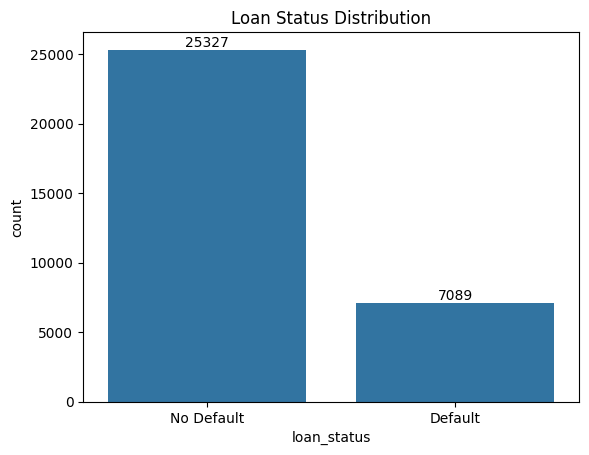

In [15]:
ax = sns.countplot(data=df,x="loan_status")
ax.bar_label(ax.containers[0])
plt.title("Loan Status Distribution")
plt.xticks([0,1],["No Default","Default"])
plt.show()

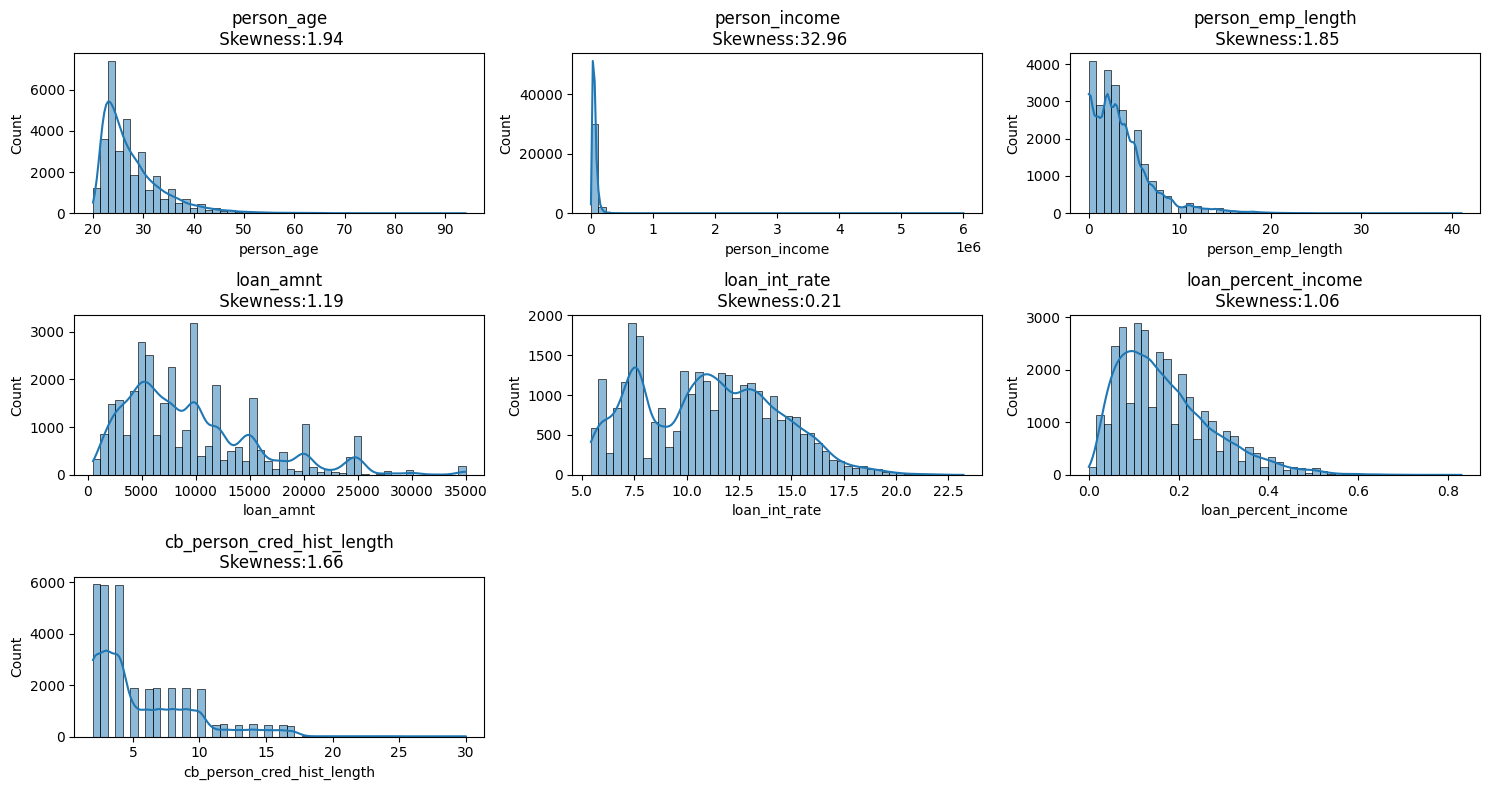

In [16]:
plt.figure(figsize=(15,8))
for i,col in enumerate(num_cols,1):
    plt.subplot(3,3,i)
    sns.histplot(data=df,x=df[col],bins=50,kde=True)
    skewness = df[col].skew()
    plt.title(f"{col}\n Skewness:{skewness:.2f}")
plt.tight_layout()
plt.show()

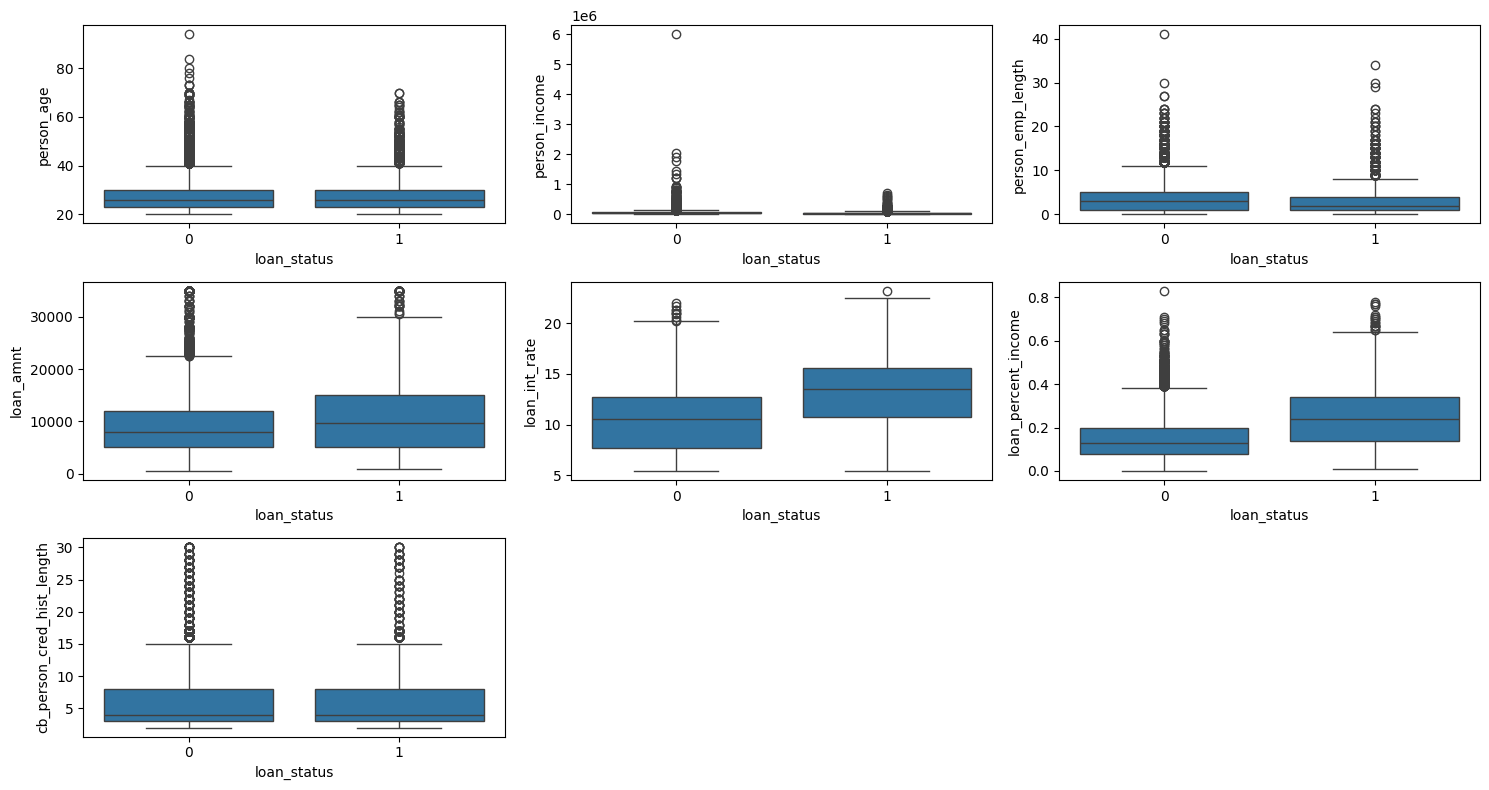

In [17]:
plt.figure(figsize=(15,8))
for i,col in enumerate(num_cols,1):
    plt.subplot(3,3,i)
    sns.boxplot(data=df,x="loan_status",y=col)
plt.tight_layout()
plt.show()

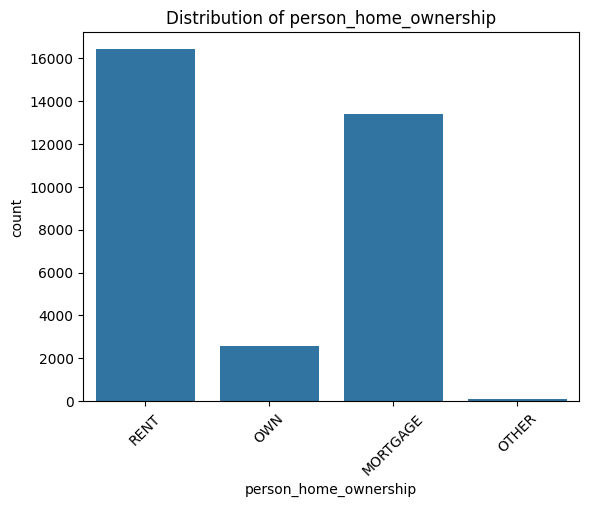

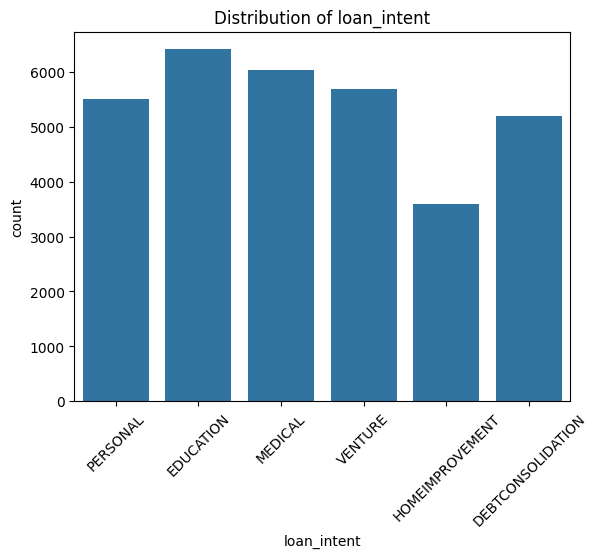

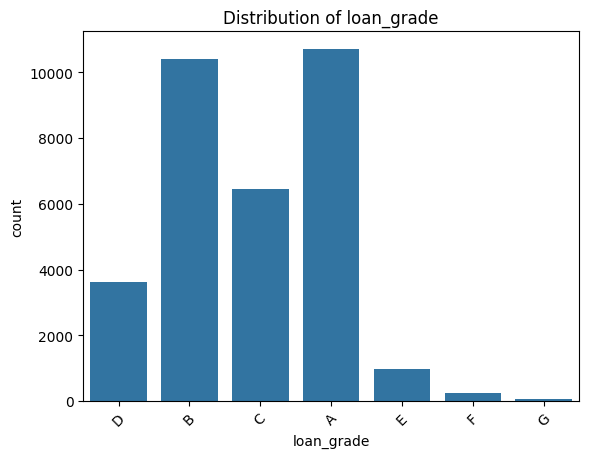

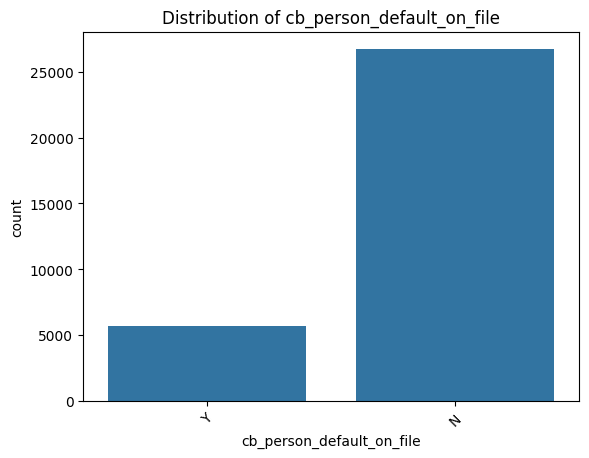

In [18]:
for col in cat_cols:
    sns.countplot(data=df,x=col)
    plt.xticks(rotation=45)
    plt.title(f"Distribution of {col}")
    plt.show()

In [19]:
pd.crosstab(df["loan_grade"],df["loan_status"],normalize="index") * 100

loan_status,0,1
loan_grade,,
A,90.040176,9.959824
B,83.681525,16.318475
C,79.248214,20.751786
D,40.939227,59.060773
E,35.514019,64.485981
F,29.460581,70.539419
G,1.562500,98.437500


In [20]:
pd.crosstab(df["loan_intent"],df["loan_status"],normalize="index")*100

loan_status,0,1
loan_intent,,
DEBTCONSOLIDATION,71.323955,28.676045
EDUCATION,82.748401,17.251599
HOMEIMPROVEMENT,73.845298,26.154702
MEDICAL,73.237339,26.762661
PERSONAL,80.101855,19.898145
VENTURE,85.146075,14.853925


In [21]:
pd.crosstab(df["person_home_ownership"],df["loan_status"],normalize="index")*100

loan_status,0,1
person_home_ownership,,
MORTGAGE,87.381255,12.618745
OTHER,68.867925,31.132075
OWN,92.508779,7.491221
RENT,68.390524,31.609476


<Axes: >

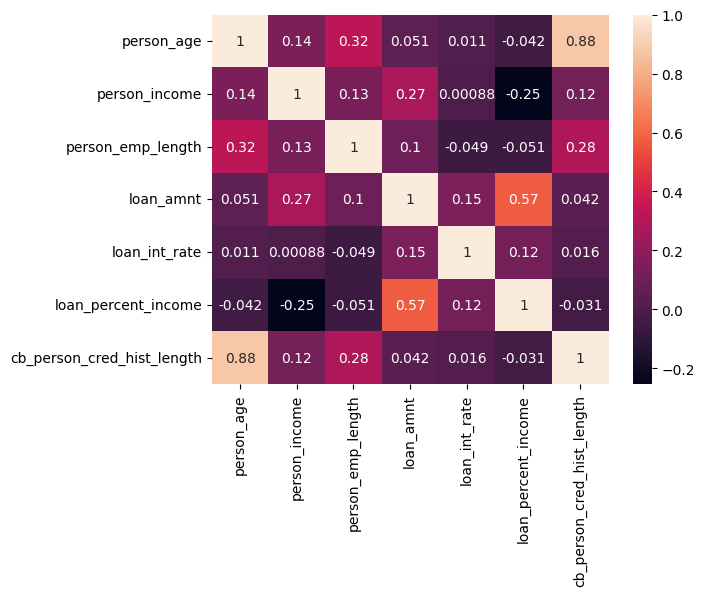

In [22]:
sns.heatmap(df[num_cols].corr(),annot=True)

In [23]:
X = df.drop(columns="loan_status")
y = df["loan_status"]

In [24]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [25]:
# Split training data into training and validation sets
X_train_fit, X_val, y_train_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)

In [26]:
# Cap income outliers using training-set percentiles
lower = X_train_fit["person_income"].quantile(0.01)
upper = X_train_fit["person_income"].quantile(0.99)

X_train_fit = X_train_fit.copy()
X_val = X_val.copy()
X_test = X_test.copy()

X_train_fit["person_income"] = X_train_fit["person_income"].clip(lower, upper)
X_val["person_income"] = X_val["person_income"].clip(lower, upper)
X_test["person_income"] = X_test["person_income"].clip(lower, upper)

In [27]:
ohe_cols = ["person_home_ownership","loan_intent","cb_person_default_on_file"]
oe_cols = ["loan_grade"]

num_pipeline = Pipeline([
    ("imputer",SimpleImputer(strategy="median")),
    ("scaler",StandardScaler())
])

cat_pipeline = Pipeline([
    ("ohe",OneHotEncoder(drop="first",handle_unknown="ignore"))
])

preprocessor_ann = ColumnTransformer([
    ("num",num_pipeline,num_cols),
    ("cat",cat_pipeline,ohe_cols),
    ("grade",OrdinalEncoder(
        categories=[["A", "B", "C", "D", "E", "F", "G"]]
    ),oe_cols)
])

In [28]:
X_train_processed = preprocessor_ann.fit_transform(X_train_fit)
X_val_processed = preprocessor_ann.transform(X_val)
X_test_processed = preprocessor_ann.transform(X_test)

In [29]:
# Oversample only the training data 
from imblearn.over_sampling import RandomOverSampler
ros = RandomOverSampler(random_state=42)
X_train_resampled, y_train_resampled = ros.fit_resample(
    X_train_processed, y_train_fit
)

In [30]:
def to_dense_array(data):
    return data.toarray() if hasattr(data, "toarray") else np.asarray(data)

X_train_tensor = torch.tensor(to_dense_array(X_train_resampled), dtype=torch.float32)
X_val_tensor = torch.tensor(to_dense_array(X_val_processed), dtype=torch.float32)
X_test_tensor = torch.tensor(to_dense_array(X_test_processed), dtype=torch.float32)

y_train_tensor = torch.tensor(np.asarray(y_train_resampled), dtype=torch.float32).reshape(-1, 1)
y_val_tensor = torch.tensor(np.asarray(y_val), dtype=torch.float32).reshape(-1, 1)
y_test_tensor = torch.tensor(np.asarray(y_test), dtype=torch.float32).reshape(-1, 1)

In [31]:
class CreditRiskANN(nn.Module):

    def __init__(self, input_features):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_features, 32),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.network(x)

input_features = X_train_tensor.shape[1]

In [32]:
model = CreditRiskANN(input_features)

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

train_dataset = TensorDataset(X_train_tensor,y_train_tensor)
train_loader = DataLoader(train_dataset,batch_size=64,shuffle=True)

Epoch [10/100] | Train Loss: 0.3823 | Validation Loss: 0.3321
Epoch [20/100] | Train Loss: 0.3566 | Validation Loss: 0.3266
Epoch [30/100] | Train Loss: 0.3485 | Validation Loss: 0.3096
Epoch [40/100] | Train Loss: 0.3464 | Validation Loss: 0.3160
Epoch [50/100] | Train Loss: 0.3456 | Validation Loss: 0.3088
Epoch [60/100] | Train Loss: 0.3442 | Validation Loss: 0.2973
Epoch [70/100] | Train Loss: 0.3436 | Validation Loss: 0.3048
Epoch [80/100] | Train Loss: 0.3428 | Validation Loss: 0.2973
Epoch [90/100] | Train Loss: 0.3409 | Validation Loss: 0.3054
Epoch [100/100] | Train Loss: 0.3398 | Validation Loss: 0.3018


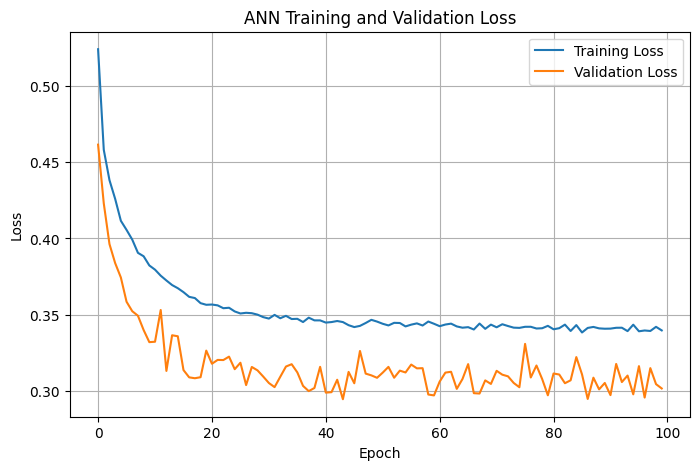

In [33]:
epochs = 100
train_losses = []
val_losses = []

for epoch in range(epochs):
    model.train()
    total_train_loss = 0
    for X_batch, y_batch in train_loader:
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_train_loss += loss.item()

    avg_train_loss = total_train_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    model.eval()
    with torch.no_grad():
        val_logits = model(X_val_tensor)
        val_loss = criterion(val_logits, y_val_tensor).item()
    val_losses.append(val_loss)

    if (epoch + 1) % 10 == 0:
        print(f"Epoch [{epoch+1}/{epochs}] | Train Loss: {avg_train_loss:.4f} | Validation Loss: {val_loss:.4f}")

# Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ANN Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [34]:
model.eval()
with torch.no_grad():
    logits = model(X_test_tensor)
    probabilities = torch.sigmoid(logits).cpu().numpy().ravel()
    y_pred = (probabilities >= 0.5).astype(int)

y_true = y_test_tensor.cpu().numpy().ravel()
accuracy = accuracy_score(y_true, y_pred)
print("ANN Accuracy:", accuracy)
print("\nClassification Report:")
print(classification_report(y_true, y_pred))
ann_auc = roc_auc_score(y_true, probabilities)
print("ANN ROC-AUC:", ann_auc)

ANN Accuracy: 0.9099321406539174

Classification Report:
              precision    recall  f1-score   support

         0.0       0.93      0.96      0.94      5066
         1.0       0.82      0.75      0.78      1418

    accuracy                           0.91      6484
   macro avg       0.88      0.85      0.86      6484
weighted avg       0.91      0.91      0.91      6484

ANN ROC-AUC: 0.9187511171297685


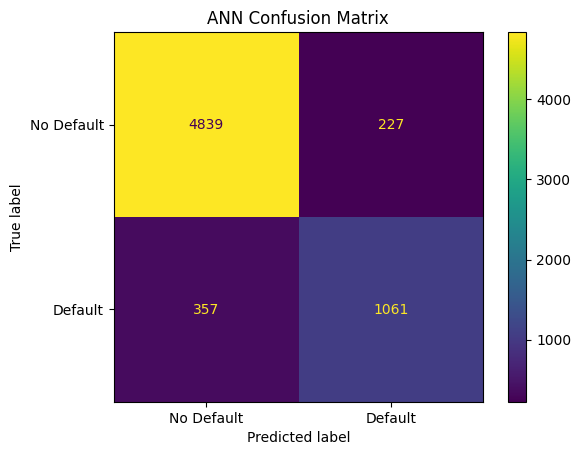

In [35]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_true, y_pred)
cm_display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Default", "Default"])
cm_display.plot()
plt.title("ANN Confusion Matrix")
plt.show()

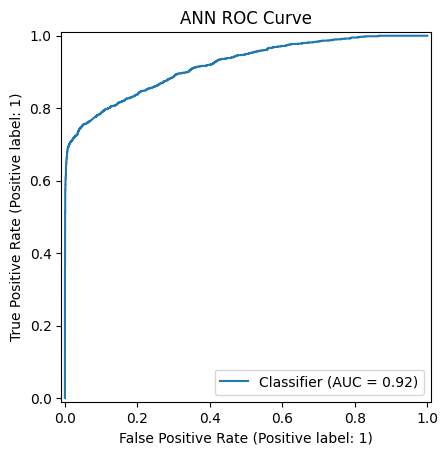

In [36]:
from sklearn.metrics import RocCurveDisplay
RocCurveDisplay.from_predictions(y_true, probabilities)
plt.title("ANN ROC Curve")
plt.show()

# Conclusion

- **The ANN model achieved 90.14% accuracy on the test dataset.**

- **The model achieved a 0.91 ROC-AUC score, indicating good class discrimination.**

- **76% of actual defaulters were correctly identified by the model.**

- **Class imbalance was handled using RandomOverSampler on the training data.**

- **The model shows potential for identifying borrowers with a higher risk of loan default.**

In [37]:
import joblib

model_data = {
    "model_state_dict": model.state_dict(),
    "preprocessor": preprocessor_ann,
    "lower": lower,
    "upper": upper,
    "input_features": input_features
}

joblib.dump(model_data, "credit_risk_model.pkl")

['credit_risk_model.pkl']